# Decoding previous image identity from mouse V1 responses to a shared visual stimulus

This notebook analyzes passive replay from four sessions in the [Allen Visual Behavior Neuropixels dataset](https://dandiarchive.org/dandiset/000713/0.240702.1725). (X_1) is the first flash after an image change. Preceding images are compared within the same current image.

Start Jupyter from the repository root. Keep `ecephys_session_1055240613_sequence_events.csv` next to this notebook and place these four Allen NWB files in `data/`: `ecephys_session_1055240613.nwb`, `ecephys_session_1067588044.nwb`, `ecephys_session_1081090969.nwb`, and `ecephys_session_1065449881.nwb`. See the [Allen download instructions](https://allensdk.readthedocs.io/en/v2.16.1/_static/examples/nb/visual_behavior_neuropixels_data_access.html).

Use Python 3.10 or later with Jupyter, NumPy, h5py, and Matplotlib. Run the cells in order. The matched analysis writes its result and Figure 1 to `results/`. The displayed numerical results are from the original analysis.

In [1]:
from pathlib import Path
from itertools import combinations
import csv

import h5py
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(".")
DATA_DIR = ROOT / "data"
SESSION = "ecephys_session_1055240613"
NWB = DATA_DIR / f"{SESSION}.nwb"
EVENTS = ROOT / f"{SESSION}_sequence_events.csv"

required = [
    EVENTS,
    NWB,
    *(DATA_DIR / f"ecephys_session_{sid}.nwb"
      for sid in (1067588044, 1081090969, 1065449881)),
]
missing = [path.as_posix() for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing input files:\n" + "\n".join(missing))

## Mouse 1 stimulus sequence table

In [2]:
def text_value(value):
    return value.decode("utf-8") if isinstance(value, bytes) else str(value)


columns = ("id", "image_name", "start_time", "stimulus_block")

with h5py.File(NWB, "r") as f:
    tables = [
        table
        for name, table in f["intervals"].items()
        if "natural_images" in name.lower()
        and all(column in table for column in columns)
    ]
    if len(tables) != 1:
        raise ValueError(f"Expected one natural-image table, found {len(tables)}.")

    stimulus = [tables[0][column][:] for column in columns]

# Block 5 is passive replay.
passive = {
    int(event_id): (text_value(image), float(onset))
    for event_id, image, onset, block in zip(*stimulus, strict=True)
    if block == 5
}

with EVENTS.open(encoding="utf-8-sig", newline="") as f:
    events = [
        row for row in csv.DictReader(f)
        if row["condition"] == "no_omission"
    ]

events.sort(key=lambda row: float(row["probe_time_s"]))

if len(events) != 154 or len({row["probe_id"] for row in events}) != 154:
    raise ValueError("Expected 154 unique no-omission sequences.")

previous_times, probe_times, history, targets = [], [], [], []

for row in events:
    previous_image, previous_onset = passive[int(row["previous_id"])]
    target_image, probe_onset = passive[int(row["probe_id"])]

    if (
        previous_image != row["previous_image"]
        or target_image != row["target_image"]
        or not np.isclose(
            probe_onset, float(row["probe_time_s"]), atol=1e-6, rtol=0
        )
    ):
        raise ValueError(f"CSV and NWB disagree at probe {row['probe_id']}.")

    previous_times.append(previous_onset)
    probe_times.append(probe_onset)
    history.append(previous_image)
    targets.append(target_image)

previous_times = np.array(previous_times)
probe_times = np.array(probe_times)
history = np.array(history)
targets = np.array(targets)

print(f"Passive presentations: {len(passive):,}")
print(f"Eligible no-omission sequences: {len(events)}")

Passive presentations: 4,800
Eligible no-omission sequences: 154


In [ ]:
def check_mouse1_sequences(nwb_path, event_rows):
    with h5py.File(nwb_path, "r") as f:
        table, = [
            group for name, group in f["intervals"].items()
            if "natural_images" in name.lower()
            and name.endswith("_presentations")
        ]
        times = table["start_time"][:]
        rows = np.flatnonzero(table["stimulus_block"][:] == 5)
        rows = rows[np.argsort(times[rows])]
        ids = table["id"][:][rows]
        times = times[rows]
        images = table["image_name"][:][rows].astype(str)
        omitted = table["omitted"][:][rows].astype(bool)
        change = table["is_change"][:][rows].astype(bool)

    slots = np.lib.stride_tricks.sliding_window_view(np.arange(len(ids)), 5)
    a, x1 = slots[:, 0], slots[:, 1]
    repeats = slots[:, 2:]
    valid = (
        change[x1]
        & ~omitted[slots].any(axis=1)
        & (images[a] != images[x1])
        & ~change[repeats].any(axis=1)
        & (images[repeats] == images[x1, None]).all(axis=1)
        & (np.abs(np.diff(times[slots], axis=1) - 0.75) <= 0.05).all(axis=1)
    )
    from_nwb = {tuple(map(int, row)) for row in ids[slots[valid]]}

    columns = ("previous_id", "change_id", "branch_id",
               "shared_flash_id", "probe_id")
    event_ids = [tuple(int(row[col]) for col in columns) for row in event_rows]
    from_csv = set(event_ids)
    if len(event_ids) != len(from_csv) or from_nwb != from_csv:
        raise ValueError(
            f"Sequence mismatch: {len(event_ids) - len(from_csv)} duplicates, "
            f"{len(from_csv - from_nwb)} CSV-only, {len(from_nwb - from_csv)} NWB-only."
        )
    print(f"{len(from_csv)} event-table sequences match the NWB stimulus table.")


check_mouse1_sequences(NWB, events)

## Mouse 1 VISp units and temporal split

In [3]:
WINDOW = (0.050, 0.250)  # Seconds after stimulus onset
onsets = np.stack([previous_times, probe_times])

with h5py.File(NWB, "r") as f:
    units = f["units"]
    electrodes = f["general/extracellular_ephys/electrodes"]

    # Link each unit's peak channel to its anatomical location.
    region_by_channel = {
        int(channel): text_value(region)
        for channel, region in zip(
            electrodes["id"][:], electrodes["location"][:], strict=True
        )
    }

    is_v1 = np.array([
        region_by_channel[int(channel)] == "VISp"
        for channel in units["peak_channel_id"][:]
    ])
    good = np.array([text_value(q) == "good" for q in units["quality"][:]])

    isi = units["isi_violations"][:]
    cutoff = units["amplitude_cutoff"][:]
    presence = units["presence_ratio"][:]

    selected = np.flatnonzero(
        is_v1 & good
        & (isi >= 0) & (isi < 0.5)
        & (cutoff >= 0) & (cutoff < 0.1)
        & (presence >= 0.9) & (presence <= 1.0)
    )
    if len(selected) == 0:
        raise ValueError("No V1 units passed the quality filters.")

    spike_data = units["spike_times"]
    offsets = np.r_[0, units["spike_times_index"][:]].astype(np.int64)

    if np.any(np.diff(offsets) < 0) or offsets[-1] != len(spike_data):
        raise ValueError("The NWB spike offsets are inconsistent.")

    features = np.empty((2, len(events), len(selected)), dtype=float)

    for j, unit_row in enumerate(selected):
        spikes = spike_data[offsets[unit_row]:offsets[unit_row + 1]]

        if np.any(~np.isfinite(spikes)) or np.any(np.diff(spikes) < 0):
            raise ValueError(f"Invalid spike times for unit row {unit_row}.")

        left = np.searchsorted(spikes, onsets + WINDOW[0])
        right = np.searchsorted(spikes, onsets + WINDOW[1])
        features[:, :, j] = right - left

print("V1 units retained:", len(selected))
print("Feature shape (epochs, sequences, units):", features.shape)

V1 units retained: 44
Feature shape (epochs, sequences, units): (2, 154, 44)


In [4]:
passive_times = [onset for _, onset in passive.values()]
midpoint = (min(passive_times) + max(passive_times)) / 2
BUFFER = 10.0  # Seconds on each side of the midpoint

# Keep the full sequence and its spike-count windows on one side.
is_early = probe_times + WINDOW[1] <= midpoint - BUFFER
is_late = previous_times >= midpoint + BUFFER

groups = {}

for target in sorted(set(targets)):
    early = np.flatnonzero((targets == target) & is_early)
    late = np.flatnonzero((targets == target) & is_late)

    shared_labels = sorted(set(history[early]) & set(history[late]))
    if len(shared_labels) < 2:
        continue

    groups[target] = (
        early[np.isin(history[early], shared_labels)],
        late[np.isin(history[late], shared_labels)],
        tuple(combinations(shared_labels, 2)),
    )

if not groups:
    raise ValueError("No current image supports a held-out comparison.")

print("Sequences retained:", sum(len(a) + len(b) for a, b, _ in groups.values()))
print("Current images:", len(groups))
print("Within-image comparisons:", sum(len(pairs) for _, _, pairs in groups.values()))

Sequences retained: 130
Current images: 8
Within-image comparisons: 114


## Mouse 1 pairwise decoding and permutation blocks

In [5]:
def balanced_score(counts, labels, train, test, label_a, label_b):
    train_a = train[labels[train] == label_a]
    train_b = train[labels[train] == label_b]
    test_a = test[labels[test] == label_a]
    test_b = test[labels[test] == label_b]

    center_a = counts[train_a].mean(axis=0)
    center_b = counts[train_b].mean(axis=0)
    direction = center_b - center_a
    center = (center_a + center_b) / 2

    scores_a = (counts[test_a] - center) @ direction
    scores_b = (counts[test_b] - center) @ direction

    # Count ties as half-correct and give both labels equal weight.
    recall_a = np.mean((scores_a < 0) + 0.5 * (scores_a == 0))
    recall_b = np.mean((scores_b > 0) + 0.5 * (scores_b == 0))
    return (recall_a + recall_b) / 2


def decode(labels):
    target_scores = []

    for early, late, pairs in groups.values():
        pair_scores = []
        for a, b in pairs:
            pair_scores.append([
                (
                    balanced_score(counts, labels, early, late, a, b)
                    + balanced_score(counts, labels, late, early, a, b)
                ) / 2
                for counts in features
            ])
        target_scores.append(np.mean(pair_scores, axis=0))

    # Each current image contributes equally to the final score.
    return np.mean(target_scores, axis=0)


observed = decode(history)

# Shuffle only within the same current image, time half, and five-minute bin.
shuffle_groups = []
for early, late, _ in groups.values():
    for indices in (early, late):
        bins = ((previous_times[indices] - midpoint) // 300).astype(int)
        for time_bin in np.unique(bins):
            subset = indices[bins == time_bin]
            if len(set(history[subset])) >= 2:
                shuffle_groups.append(subset)

if not shuffle_groups:
    raise ValueError("No time bin has two labels to shuffle.")

rng = np.random.default_rng(1055240613)
null = np.empty((199, 2))

for i in range(len(null)):
    shuffled = history.copy()
    for subset in shuffle_groups:
        shuffled[subset] = rng.permutation(history[subset])
    null[i] = decode(shuffled)

epoch_names = ("Previous image on screen", "Shared probe")
limits = np.quantile(null, [0.025, 0.975], axis=0)

for j, name in enumerate(epoch_names):
    print(
        f"{name}: {observed[j]:.1%} "
        f"| shuffled reference: {limits[0, j]:.1%}–{limits[1, j]:.1%}"
    )

Previous image on screen: 88.2% | shuffled reference: 54.9%–70.0%
Shared probe: 50.5% | shuffled reference: 43.1%–55.1%


## Mouse 1 descriptive decoding across flashes

In [7]:
flash_columns = ("change_id", "branch_id", "shared_flash_id", "probe_id")
flash_names = (
    "X1: first target",
    "X2: first repeat",
    "X3: second repeat",
    "X4: final probe",
)
flash_onsets = np.empty((4, len(events)), dtype=float)

for j, event in enumerate(events):
    for k, column in enumerate(flash_columns):
        image, onset = passive[int(event[column])]
        if image != event["target_image"]:
            raise ValueError(
                f"Unexpected image in {column} for probe {event['probe_id']}."
            )
        flash_onsets[k, j] = onset

if not np.allclose(np.diff(flash_onsets, axis=0), 0.75, atol=0.05, rtol=0):
    raise ValueError("Unexpected spacing between target flashes.")

np.testing.assert_allclose(flash_onsets[-1], probe_times, atol=1e-6, rtol=0)

# Count V1 spikes in the same 50–250 ms window at each flash.
flash_features = np.empty((4, len(events), len(selected)), dtype=float)

with h5py.File(NWB, "r") as f:
    spike_data = f["units/spike_times"]
    for j, unit_row in enumerate(selected):
        spikes = spike_data[offsets[unit_row]:offsets[unit_row + 1]]
        left = np.searchsorted(spikes, flash_onsets + WINDOW[0])
        right = np.searchsorted(spikes, flash_onsets + WINDOW[1])
        flash_features[:, :, j] = right - left

# Compare the X4 spike counts with the original probe counts.
np.testing.assert_array_equal(flash_features[-1], features[1])


def decode_flashes(labels):
    target_scores = []

    for early, late, pairs in groups.values():
        pair_scores = [
            [
                (
                    balanced_score(counts, labels, early, late, a, b)
                    + balanced_score(counts, labels, late, early, a, b)
                ) / 2
                for counts in flash_features
            ]
            for a, b in pairs
        ]
        target_scores.append(np.mean(pair_scores, axis=0))

    return np.mean(target_scores, axis=0)


flash_scores = decode_flashes(history)
rng_flash = np.random.default_rng(1055240613)
flash_null = np.empty((len(null), 4))

for i in range(len(flash_null)):
    shuffled = history.copy()
    for subset in shuffle_groups:
        shuffled[subset] = rng_flash.permutation(history[subset])
    flash_null[i] = decode_flashes(shuffled)

# Compare the X4 scores and shuffles with the original probe analysis.
np.testing.assert_allclose(flash_scores[-1], observed[1], atol=1e-12, rtol=0)
np.testing.assert_allclose(flash_null[:, -1], null[:, 1], atol=1e-12, rtol=0)

flash_limits = np.quantile(flash_null, [0.025, 0.975], axis=0)
lag_s = np.median(flash_onsets - flash_onsets[0], axis=1)

for k, name in enumerate(flash_names):
    print(
        f"{name} ({lag_s[k]:.2f} s): {flash_scores[k]:.1%}"
        f" | shuffled: {flash_limits[0, k]:.1%}–{flash_limits[1, k]:.1%}"
    )

X1: first target (0.00 s): 53.1% | shuffled: 45.9%–57.8%
X2: first repeat (0.75 s): 52.1% | shuffled: 44.7%–53.6%
X3: second repeat (1.50 s): 49.1% | shuffled: 45.1%–54.1%
X4: final probe (2.25 s): 50.5% | shuffled: 43.1%–55.1%


In [8]:
# Decode the current image while holding the previous image fixed.
early_pool = np.sort(np.concatenate([g[0] for g in groups.values()]))
late_pool = np.sort(np.concatenate([g[1] for g in groups.values()]))
current_groups = {}

for prev in np.intersect1d(history[early_pool], history[late_pool]):
    e = early_pool[history[early_pool] == prev]
    l = late_pool[history[late_pool] == prev]
    shared = np.intersect1d(targets[e], targets[l])
    if len(shared) >= 2:
        current_groups[prev] = (
            e[np.isin(targets[e], shared)],
            l[np.isin(targets[l], shared)],
            tuple(combinations(shared, 2)),
        )

if not current_groups:
    raise ValueError("No previous image supports a held-out current-image comparison.")

def decode_current(labels):
    return np.mean([
        np.mean([
            [(balanced_score(X, labels, e, l, a, b)
              + balanced_score(X, labels, l, e, a, b)) / 2
             for X in flash_features]
            for a, b in pairs
        ], axis=0)
        for e, l, pairs in current_groups.values()
    ], axis=0)

# Shuffle within each previous image, recording half, and five-minute bin.
current_shuffle = []
time_bin = np.floor((flash_onsets[0] - flash_onsets[0].min()) / 300).astype(int)
for e, l, _ in current_groups.values():
    for half in (e, l):
        for b in np.unique(time_bin[half]):
            ids = half[time_bin[half] == b]
            if np.unique(targets[ids]).size >= 2:
                current_shuffle.append(ids)

if not current_shuffle:
    raise ValueError("No time bin supports a current-image label shuffle.")

current_scores = decode_current(targets)
current_null = np.empty((len(null), len(flash_names)))
rng_current = np.random.default_rng(1055240614)

for i in range(len(current_null)):
    permuted = targets.copy()
    for ids in current_shuffle:
        permuted[ids] = rng_current.permutation(targets[ids])
    current_null[i] = decode_current(permuted)

current_lo, current_hi = np.quantile(current_null, [0.025, 0.975], axis=0)

print("Retained sequences:", sum(len(e) + len(l) for e, l, _ in current_groups.values()))
print("Previous images:", len(current_groups))
print("Within-history pairs:", sum(len(pairs) for _, _, pairs in current_groups.values()))

for name, score, lo, hi in zip(flash_names, current_scores, current_lo, current_hi):
    print(f"{name} | current image {score:.1%} | shuffled {lo:.1%}–{hi:.1%}")

Retained sequences: 130
Previous images: 8
Within-history pairs: 106
X1: first target | current image 96.8% | shuffled 60.5%–75.2%
X2: first repeat | current image 94.9% | shuffled 59.1%–73.1%
X3: second repeat | current image 92.0% | shuffled 59.9%–72.4%
X4: final probe | current image 91.9% | shuffled 58.4%–72.5%


## Exploratory timing analysis in mouse 1

In [9]:
# Previous-image decoding around the first shared flash (X1).
edges_ms = np.arange(-250, 251, 50)
x1_edges = flash_onsets[0, :, None] + edges_ms[None, :] / 1000
x1_counts = np.empty((len(edges_ms) - 1, len(events), len(selected)))

with h5py.File(NWB, "r") as f:
    spike_data = f["units"]["spike_times"]
    for j, row in enumerate(selected):
        spikes = spike_data[offsets[row]:offsets[row + 1]]
        edge_indices = np.searchsorted(spikes, x1_edges)
        x1_counts[:, :, j] = np.diff(edge_indices, axis=1).T

post_x1 = edges_ms[:-1] >= 0
original_x1 = edges_ms[:-1] >= 50
np.testing.assert_array_equal(
    x1_counts[original_x1].sum(axis=0), flash_features[0]
)

def decode_x1_history(labels):
    by_target = []
    for e, l, pairs in groups.values():
        pair_scores = [
            [(balanced_score(counts, labels, e, l, a, b)
              + balanced_score(counts, labels, l, e, a, b)) / 2
             for counts in x1_counts]
            for a, b in pairs
        ]
        by_target.append(np.mean(pair_scores, axis=0))
    return np.mean(by_target, axis=0)

x1_observed = decode_x1_history(history)
x1_null = np.empty((len(null), len(x1_observed)))
rng_x1 = np.random.default_rng(1055240613)

for i in range(len(x1_null)):
    shuffled = history.copy()
    for ids in shuffle_groups:
        shuffled[ids] = rng_x1.permutation(history[ids])
    x1_null[i] = decode_x1_history(shuffled)

# Compare the largest post-onset excess over the bin-specific reference.
x1_center = np.vstack((x1_observed, x1_null)).mean(axis=0)
x1_obs_max = (x1_observed - x1_center)[post_x1].max()
x1_null_max = (x1_null - x1_center)[:, post_x1].max(axis=1)
x1_p = (1 + np.count_nonzero(x1_null_max >= x1_obs_max)) / (len(x1_null) + 1)

x1_lo, x1_hi = np.quantile(x1_null, [0.025, 0.975], axis=0)
for left, right, score, lo, hi in zip(
    edges_ms[:-1], edges_ms[1:], x1_observed, x1_lo, x1_hi
):
    print(f"{left:+4d} to {right:+4d} ms | {score:5.1%} | shuffled {lo:.1%}–{hi:.1%}")

print(f"Post-onset max-statistic shuffle p = {x1_p:.3f}")

-250 to -200 ms | 51.4% | shuffled 46.4%–55.8%
-200 to -150 ms | 49.1% | shuffled 43.6%–53.6%
-150 to -100 ms | 50.2% | shuffled 44.3%–55.5%
-100 to  -50 ms | 49.4% | shuffled 45.5%–56.0%
 -50 to   +0 ms | 57.5% | shuffled 47.0%–56.6%
  +0 to  +50 ms | 54.6% | shuffled 46.0%–56.7%
 +50 to +100 ms | 56.7% | shuffled 49.5%–59.1%
+100 to +150 ms | 54.4% | shuffled 47.0%–56.5%
+150 to +200 ms | 50.5% | shuffled 46.2%–56.2%
+200 to +250 ms | 48.6% | shuffled 44.9%–55.2%
Post-onset max-statistic shuffle p = 0.260


## Mouse 2 sequence selection and decoding

In [10]:
# Prepare matched trials in an independent mouse.
rep_id = 1067588044
rep_nwb = ROOT / "data" / f"ecephys_session_{rep_id}.nwb"

if not rep_nwb.is_file():
    raise FileNotFoundError(f"Put the downloaded NWB here: {rep_nwb}")

with h5py.File(rep_nwb, "r") as f:
    table, = [
        g for name, g in f["intervals"].items()
        if "natural_images" in name.lower() and name.endswith("_presentations")
    ]
    all_times = table["start_time"][:]
    rows = np.flatnonzero(table["stimulus_block"][:] == 5)
    rows = rows[np.argsort(all_times[rows])]
    times = all_times[rows]
    images = table["image_name"][:][rows].astype(str)
    omitted = table["omitted"][:][rows].astype(bool)
    change = table["is_change"][:][rows].astype(bool)

# A → X1 → X2 → X3 → X4, with no omissions.
rep_slots = np.lib.stride_tricks.sliding_window_view(np.arange(len(times)), 5)
a, x1, x2, x3, x4 = rep_slots.T
valid = (
    change[x1]
    & ~omitted[rep_slots].any(axis=1)
    & (images[a] != images[x1])
    & ~change[rep_slots[:, 2:]].any(axis=1)
    & (images[rep_slots[:, 2:]] == images[x1, None]).all(axis=1)
    & (np.abs(np.diff(times[rep_slots], axis=1) - 0.75) <= 0.05).all(axis=1)
)

rep_times = times[rep_slots[valid]]
rep_history = images[a[valid]]
rep_target = images[x1[valid]]

rep_mid = (times[0] + times[-1]) / 2
rep_early = rep_times[:, -1] + WINDOW[1] <= rep_mid - 10
rep_late = rep_times[:, 0] >= rep_mid + 10
rep_groups = {}

for x in np.unique(rep_target):
    e = np.flatnonzero((rep_target == x) & rep_early)
    l = np.flatnonzero((rep_target == x) & rep_late)
    labels = np.intersect1d(rep_history[e], rep_history[l])
    if len(labels) >= 2:
        rep_groups[x] = (
            e[np.isin(rep_history[e], labels)],
            l[np.isin(rep_history[l], labels)],
            tuple(combinations(labels, 2)),
        )

print(f"Passive presentations: {len(times):,}")
print(f"Eligible no-omission sequences: {len(rep_times)}")
print(f"Retained sequences: {sum(len(e) + len(l) for e, l, _ in rep_groups.values())}")
print(f"Current images: {len(rep_groups)}")
print(f"Within-image comparisons: {sum(len(p) for _, _, p in rep_groups.values())}")

Passive presentations: 4,805
Eligible no-omission sequences: 205
Retained sequences: 197
Current images: 8
Within-image comparisons: 151


In [11]:
# Repeat the V1 history decoder in mouse 544836.
with h5py.File(rep_nwb, "r") as f:
    rep_units = f["units"]
    rep_electrodes = f["general/extracellular_ephys/electrodes"]
    rep_location = dict(zip(rep_electrodes["id"][:],
                            rep_electrodes["location"][:].astype(str)))
    rep_in_v1 = np.array([rep_location[k] == "VISp"
                          for k in rep_units["peak_channel_id"][:]])
    rep_isi = rep_units["isi_violations"][:]
    rep_cutoff = rep_units["amplitude_cutoff"][:]
    rep_presence = rep_units["presence_ratio"][:]
    rep_selected = np.flatnonzero(
        rep_in_v1 & (rep_units["quality"][:].astype(str) == "good")
        & (0 <= rep_isi) & (rep_isi < 0.5)
        & (0 <= rep_cutoff) & (rep_cutoff < 0.1)
        & (0.9 <= rep_presence) & (rep_presence <= 1)
    )
    if not rep_selected.size:
        raise ValueError("No VISp units passed the quality filters.")

    rep_spike_data = rep_units["spike_times"]
    rep_offsets = np.r_[0, rep_units["spike_times_index"][:]].astype(np.int64)
    if np.any(np.diff(rep_offsets) < 0) or rep_offsets[-1] != len(rep_spike_data):
        raise ValueError("Invalid NWB spike-time offsets.")

    rep_counts = np.empty((5, len(rep_times), len(rep_selected)))
    for j, row in enumerate(rep_selected):
        spikes = rep_spike_data[rep_offsets[row]:rep_offsets[row + 1]]
        if not np.isfinite(spikes).all() or np.any(np.diff(spikes) < 0):
            raise ValueError(f"Invalid spike times for unit row {row}.")
        lo = np.searchsorted(spikes, rep_times.T + WINDOW[0])
        hi = np.searchsorted(spikes, rep_times.T + WINDOW[1])
        rep_counts[:, :, j] = hi - lo

def rep_decode_history(counts_by_epoch, labels):
    by_target = []
    for early, late, pairs in rep_groups.values():
        pair_scores = [
            [(balanced_score(counts, labels, early, late, a, b)
              + balanced_score(counts, labels, late, early, a, b)) / 2
             for counts in counts_by_epoch]
            for a, b in pairs
        ]
        by_target.append(np.mean(pair_scores, axis=0))
    return np.mean(by_target, axis=0)

# Preserve the target image, recording half, and five-minute time bin.
rep_shuffle_groups = []
for early, late, _ in rep_groups.values():
    for half in (early, late):
        bins = ((rep_times[half, 0] - rep_mid) // 300).astype(int)
        for b in np.unique(bins):
            ids = half[bins == b]
            if np.unique(rep_history[ids]).size >= 2:
                rep_shuffle_groups.append(ids)

if not rep_shuffle_groups:
    raise ValueError("No time bin supports a history-label shuffle.")

rep_scores = rep_decode_history(rep_counts, rep_history)
rep_null = np.empty((len(null), len(rep_scores)))
rng_rep = np.random.default_rng(rep_id)

for i in range(len(rep_null)):
    labels = rep_history.copy()
    for ids in rep_shuffle_groups:
        labels[ids] = rng_rep.permutation(rep_history[ids])
    rep_null[i] = rep_decode_history(rep_counts, labels)

rep_lo, rep_hi = np.quantile(rep_null, [0.025, 0.975], axis=0)
print(f"VISp units retained: {len(rep_selected)}")
for name, score, lo, hi in zip(
    ("Previous image on screen", *flash_names), rep_scores, rep_lo, rep_hi
):
    print(f"{name} | history {score:.1%} | shuffled {lo:.1%}–{hi:.1%}")

VISp units retained: 98
Previous image on screen | history 94.2% | shuffled 48.4%–60.0%
X1: first target | history 55.3% | shuffled 45.4%–54.9%
X2: first repeat | history 54.3% | shuffled 43.8%–53.2%
X3: second repeat | history 51.8% | shuffled 45.5%–54.5%
X4: final probe | history 52.3% | shuffled 44.6%–52.7%


## Exploratory timing analysis in mouse 2

In [12]:
# Joint test across X1–X4 and time-resolved X1 replication.
def max_shuffle_p(observed, shuffled):
    all_scores = np.vstack((observed, shuffled))
    centered = all_scores - all_scores.mean(axis=0)
    peak = centered.max(axis=1)
    return (1 + np.count_nonzero(peak[1:] >= peak[0])) / len(peak)

rep_flash_p = max_shuffle_p(rep_scores[1:], rep_null[:, 1:])
print(f"X1–X4 max-statistic shuffle p = {rep_flash_p:.3f}")

rep_edges_ms = np.arange(-250, 251, 50)
rep_x1_edges = rep_times[:, 1, None] + rep_edges_ms[None, :] / 1000
rep_x1_counts = np.empty((len(rep_edges_ms) - 1, len(rep_times), len(rep_selected)))

with h5py.File(rep_nwb, "r") as f:
    spike_data = f["units"]["spike_times"]
    for j, row in enumerate(rep_selected):
        spikes = spike_data[rep_offsets[row]:rep_offsets[row + 1]]
        edge_indices = np.searchsorted(spikes, rep_x1_edges)
        rep_x1_counts[:, :, j] = np.diff(edge_indices, axis=1).T

np.testing.assert_array_equal(
    rep_x1_counts[rep_edges_ms[:-1] >= 50].sum(axis=0), rep_counts[1]
)

rep_x1_observed = rep_decode_history(rep_x1_counts, rep_history)
rep_x1_null = np.empty((len(rep_null), len(rep_x1_observed)))
rng_x1_rep = np.random.default_rng(rep_id)

for i in range(len(rep_x1_null)):
    labels = rep_history.copy()
    for ids in rep_shuffle_groups:
        labels[ids] = rng_x1_rep.permutation(rep_history[ids])
    rep_x1_null[i] = rep_decode_history(rep_x1_counts, labels)

rep_post = rep_edges_ms[:-1] >= 0
rep_x1_p = max_shuffle_p(rep_x1_observed[rep_post], rep_x1_null[:, rep_post])
rep_x1_lo, rep_x1_hi = np.quantile(rep_x1_null, [0.025, 0.975], axis=0)

for left, right, score, lo, hi in zip(
    rep_edges_ms[:-1], rep_edges_ms[1:], rep_x1_observed, rep_x1_lo, rep_x1_hi
):
    print(f"{left:+4d} to {right:+4d} ms | {score:5.1%} | shuffled {lo:.1%}–{hi:.1%}")

print(f"X1 post-onset max-statistic shuffle p = {rep_x1_p:.3f}")

X1–X4 max-statistic shuffle p = 0.025
-250 to -200 ms | 57.6% | shuffled 45.4%–54.8%
-200 to -150 ms | 51.4% | shuffled 46.6%–54.1%
-150 to -100 ms | 49.0% | shuffled 45.3%–53.4%
-100 to  -50 ms | 50.1% | shuffled 46.2%–55.7%
 -50 to   +0 ms | 50.5% | shuffled 45.1%–55.4%
  +0 to  +50 ms | 50.5% | shuffled 45.3%–54.3%
 +50 to +100 ms | 49.1% | shuffled 46.1%–54.3%
+100 to +150 ms | 56.8% | shuffled 45.0%–54.2%
+150 to +200 ms | 53.8% | shuffled 45.6%–54.9%
+200 to +250 ms | 55.5% | shuffled 45.8%–55.0%
X1 post-onset max-statistic shuffle p = 0.015


## Mouse 2 current-image decoding

In [13]:
# Decode the current image in mouse 2, holding history fixed.
rep_e_pool = np.sort(np.concatenate([g[0] for g in rep_groups.values()]))
rep_l_pool = np.sort(np.concatenate([g[1] for g in rep_groups.values()]))
rep_current_groups = {}

for prev in np.intersect1d(rep_history[rep_e_pool], rep_history[rep_l_pool]):
    e = rep_e_pool[rep_history[rep_e_pool] == prev]
    l = rep_l_pool[rep_history[rep_l_pool] == prev]
    shared = np.intersect1d(rep_target[e], rep_target[l])
    if len(shared) >= 2:
        rep_current_groups[prev] = (
            e[np.isin(rep_target[e], shared)],
            l[np.isin(rep_target[l], shared)],
            tuple(combinations(shared, 2)),
        )

if not rep_current_groups:
    raise ValueError("No previous image supports a held-out current-image comparison.")

def rep_decode_current(labels):
    by_history = []
    for e, l, pairs in rep_current_groups.values():
        pair_scores = [
            [(balanced_score(counts, labels, e, l, a, b)
              + balanced_score(counts, labels, l, e, a, b)) / 2
             for counts in rep_counts[1:]]
            for a, b in pairs
        ]
        by_history.append(np.mean(pair_scores, axis=0))
    return np.mean(by_history, axis=0)

# Shuffle within previous image, recording half, and five-minute bin.
rep_current_shuffle = []
x1_onset = rep_times[:, 1]
rep_current_bin = np.floor((x1_onset - x1_onset.min()) / 300).astype(int)

for e, l, _ in rep_current_groups.values():
    for half in (e, l):
        for b in np.unique(rep_current_bin[half]):
            ids = half[rep_current_bin[half] == b]
            if np.unique(rep_target[ids]).size >= 2:
                rep_current_shuffle.append(ids)

if not rep_current_shuffle:
    raise ValueError("No time bin supports a current-image label shuffle.")

rep_current_scores = rep_decode_current(rep_target)
rep_current_null = np.empty((len(rep_null), len(flash_names)))
rng_rep_current = np.random.default_rng(rep_id + 1)

for i in range(len(rep_current_null)):
    labels = rep_target.copy()
    for ids in rep_current_shuffle:
        labels[ids] = rng_rep_current.permutation(rep_target[ids])
    rep_current_null[i] = rep_decode_current(labels)

lo, hi = np.quantile(rep_current_null, [0.025, 0.975], axis=0)
print("Retained sequences:", sum(len(e) + len(l)
                                for e, l, _ in rep_current_groups.values()))
for name, score, lower, upper in zip(flash_names, rep_current_scores, lo, hi):
    print(f"{name} | current image {score:.1%} | shuffled {lower:.1%}–{upper:.1%}")

Retained sequences: 197
X1: first target | current image 98.1% | shuffled 49.5%–64.8%
X2: first repeat | current image 98.1% | shuffled 49.5%–63.2%
X3: second repeat | current image 97.5% | shuffled 50.0%–63.1%
X4: final probe | current image 95.7% | shuffled 49.9%–63.1%


## Exploratory matching in the first two recordings

In [14]:
# Match VISp unit counts and trial support across mice.
def match_recordings(groups1, labels1, counts1, groups2, labels2, counts2,
                     draws=100, seed=1067588045):
    strata = {}
    for target in sorted(groups1.keys() & groups2.keys()):
        early1, late1, _ = groups1[target]
        early2, late2, _ = groups2[target]
        shared = sorted(set(labels1[early1]) & set(labels1[late1])
                        & set(labels2[early2]) & set(labels2[late2]))
        if len(shared) < 2:
            continue

        strata[target] = []
        for prev in shared:
            for half, (pool1, pool2) in enumerate(((early1, early2), (late1, late2))):
                ids1 = pool1[labels1[pool1] == prev]
                ids2 = pool2[labels2[pool2] == prev]
                strata[target].append((half, ids1, ids2, min(len(ids1), len(ids2))))

    if not strata:
        raise ValueError("No common target supports two histories in both mice.")

    n_units = min(counts1.shape[2], counts2.shape[2])
    n_trials = sum(row[3] for rows in strata.values() for row in rows)
    rng = np.random.default_rng(seed)
    scores = np.empty((draws, 2, counts1.shape[0]))

    for i in range(draws):
        for m, (counts, labels) in enumerate(((counts1, labels1), (counts2, labels2))):
            cols = rng.choice(counts.shape[2], n_units, replace=False)
            X = counts[:, :, cols]
            by_target = []

            for rows in strata.values():
                halves = [[], []]
                for half, ids1, ids2, n in rows:
                    pool = (ids1, ids2)[m]
                    halves[half].append(rng.choice(pool, n, replace=False))

                e, l = [np.concatenate(parts) for parts in halves]
                pairs = combinations(np.unique(labels[e]), 2)
                by_target.append(np.mean([
                    [(balanced_score(Y, labels, e, l, a, b)
                      + balanced_score(Y, labels, l, e, a, b)) / 2
                     for Y in X]
                    for a, b in pairs
                ], axis=0))

            scores[i, m] = np.mean(by_target, axis=0)

    return scores, n_units, n_trials, len(strata)

pilot_epochs = np.concatenate((features[:1], flash_features), axis=0)
matched, matched_units, matched_trials, matched_targets = match_recordings(
    groups, history, pilot_epochs, rep_groups, rep_history, rep_counts
)

print(f"Per mouse: {matched_units} units, {matched_trials} sequences, "
      f"{matched_targets} current images")

for k, name in enumerate(("Previous image on screen", *flash_names)):
    med = np.median(matched[:, :, k], axis=0)
    lo, hi = np.quantile(matched[:, :, k], [0.05, 0.95], axis=0)
    print(f"{name} | mouse 1 {med[0]:.1%} [{lo[0]:.1%}, {hi[0]:.1%}]"
          f" | mouse 2 {med[1]:.1%} [{lo[1]:.1%}, {hi[1]:.1%}]")

Per mouse: 44 units, 117 sequences, 8 current images
Previous image on screen | mouse 1 86.7% [84.7%, 88.7%] | mouse 2 85.4% [77.8%, 91.9%]
X1: first target | mouse 1 54.2% [50.8%, 57.2%] | mouse 2 54.0% [50.1%, 60.1%]
X2: first repeat | mouse 1 51.6% [49.4%, 54.1%] | mouse 2 50.2% [45.7%, 54.4%]
X3: second repeat | mouse 1 49.8% [47.2%, 52.0%] | mouse 2 52.0% [46.9%, 57.2%]
X4: final probe | mouse 1 49.6% [47.1%, 52.1%] | mouse 2 51.8% [47.5%, 56.6%]


In [17]:
# Fast matched permutation test
import time

def run_cell14(draws=100, permutations=199):
    started = time.perf_counter()
    print(f"Cell 14 started | {draws} draws × {permutations} shuffles", flush=True)

    mice = ((groups, history, pilot_epochs, shuffle_groups),
            (rep_groups, rep_history, rep_counts, rep_shuffle_groups))

    # Match each current × previous image transition within each recording half.
    strata = []
    for target in sorted(groups.keys() & rep_groups.keys()):
        pools = [g[target][:2] for g, _, _, _ in mice]
        shared = sorted(set.intersection(*[
            set(labels[ids])
            for (_, labels, _, _), halves in zip(mice, pools)
            for ids in halves
        ]))
        if len(shared) < 2:
            continue

        sizes = np.array([
            [min(np.count_nonzero(labels[halves[h]] == prev)
                 for (_, labels, _, _), halves in zip(mice, pools))
             for prev in shared]
            for h in range(2)
        ])
        strata.append((pools, shared, sizes))

    n_trials = sum(sizes.sum() for _, _, sizes in strata)
    if (len(strata), n_trials) != (matched_targets, matched_trials):
        raise ValueError("Matched trial support does not agree with Cell 13.")

    # Reuse the same random unit draws and within-class ranks for every shuffle.
    rng = np.random.default_rng(1067588045)
    n_units = matched_units
    unit_draws = [[], []]
    ranks = [[[] for _ in strata] for _ in mice]

    for _ in range(draws):
        for m, (_, labels, counts, _) in enumerate(mice):
            unit_draws[m].append(rng.choice(counts.shape[2], n_units, replace=False))
            for j, (pools, shared, sizes) in enumerate(strata):
                draw = [[], []]
                for k, prev in enumerate(shared):
                    for h in range(2):
                        count = np.count_nonzero(labels[pools[m][h]] == prev)
                        draw[h].append(rng.choice(count, sizes[h, k], replace=False))
                ranks[m][j].append(draw)

    unit_draws = [np.asarray(u) for u in unit_draws]
    plans = [[], []]

    for m in range(2):
        for j, (pools, shared, sizes) in enumerate(strata):
            ia, ib = np.triu_indices(len(shared), k=1)
            halves = []
            for h in range(2):
                rank = [np.stack([r[h][k] for r in ranks[m][j]])
                        for k in range(len(shared))]
                pos = np.repeat(np.arange(len(shared)), sizes[h])
                mask = (pos[:, None] == np.arange(len(shared))).astype(float)
                halves.append((pools[m][h], rank, mask, sizes[h]))
            plans[m].append((shared, ia, ib, halves))

    def decode(m, labels):
        counts = mice[m][2]
        cols = unit_draws[m]
        result = []
        for shared, ia, ib, halves in plans[m]:
            X, sums = [], []
            for pool, rank, mask, _ in halves:
                ids = np.concatenate([
                    pool[labels[pool] == prev][r]
                    for prev, r in zip(shared, rank)
                ], axis=1)
                values = counts[:, ids[..., None], cols[:, None, :]].transpose(1, 0, 2, 3)
                X.append(values)
                sums.append(mask.T @ values)

            scores = []
            for tr, te in ((0, 1), (1, 0)):
                n = halves[tr][3]
                a = sums[tr][..., ia, :] * n[ib, None]
                b = sums[tr][..., ib, :] * n[ia, None]
                direction = b - a
                scale = 2 * n[ia] * n[ib]
                margin = ((X[te] @ direction.swapaxes(-1, -2)) * scale
                          - np.sum((a + b) * direction, axis=-1)[..., None, :])

                mask, n_test = halves[te][2:]
                tied = 0.5 * (margin == 0)
                hit_a = np.sum(((margin < 0) + tied) * mask[:, ia], axis=-2) / n_test[ia]
                hit_b = np.sum(((margin > 0) + tied) * mask[:, ib], axis=-2) / n_test[ib]
                scores.append((hit_a + hit_b).mean(axis=-1) / 2)

            result.append((scores[0] + scores[1]) / 2)

        return np.mean(result, axis=0)

    observed = np.stack([decode(m, mouse[1]) for m, mouse in enumerate(mice)], axis=1)
    obs = np.median(observed, axis=0)
    difference = np.max(np.abs(obs - np.median(matched[:draws], axis=0)))
    print(f"Observed scores ready | max change vs Cell 13: {100*difference:.3f} pp",
          flush=True)

    # Shuffle history labels within current image × half × five-minute bin.
    rng = np.random.default_rng(1055240613)
    shuffled = np.empty((permutations, 2, 5))
    for i in range(permutations):
        for m, (_, labels, _, blocks) in enumerate(mice):
            perm = labels.copy()
            for ids in blocks:
                perm[ids] = rng.permutation(labels[ids])
            shuffled[i, m] = np.median(decode(m, perm), axis=0)
        if i == 0 or (i + 1) % 10 == 0 or i + 1 == permutations:
            print(f"Completed {i+1}/{permutations} | "
                  f"{time.perf_counter()-started:.1f} s elapsed", flush=True)

    p = (1 + (shuffled >= obs).sum(axis=0)) / (permutations + 1)
    raw = p[:, 1:].ravel()
    order = np.argsort(raw)
    holm = np.empty_like(raw)
    holm[order] = np.minimum(1, np.maximum.accumulate(raw[order] * np.arange(8, 0, -1)))
    holm = holm.reshape(2, 4)

    lo, hi = np.quantile(shuffled, [0.025, 0.975], axis=0)
    for m in range(2):
        print(f"\nMouse {m+1} | {n_units} units | {n_trials} sequences")
        for k, name in enumerate(("Previous image on screen", *flash_names)):
            adj = f" | Holm p={holm[m, k-1]:.3f}" if k else ""
            print(f"{name} | {obs[m,k]:.1%} | shuffled {lo[m,k]:.1%}–{hi[m,k]:.1%}"
                  f" | p={p[m,k]:.3f}{adj}")
        print(f"X4 minus X1, descriptive: {100*(obs[m,4]-obs[m,1]):+.2f} pp")

    print("\nCell 14 completed successfully.", flush=True)
    return {"observed_draws": observed, "observed_median": obs,
            "shuffle_medians": shuffled, "p": p, "holm": holm}

cell14_results = run_cell14()

Cell 14 started | 100 draws × 199 shuffles
Observed scores ready | max change vs Cell 13: 0.000 pp

Mouse 1 | 44 units | 117 sequences
Previous image on screen | 86.7% | shuffled 53.4%–69.4% | p=0.005
X1: first target | 54.2% | shuffled 45.6%–58.6% | p=0.240 | Holm p=1.000
X2: first repeat | 51.6% | shuffled 45.5%–55.2% | p=0.275 | Holm p=1.000
X3: second repeat | 49.8% | shuffled 44.1%–54.8% | p=0.395 | Holm p=1.000
X4: final probe | 49.6% | shuffled 44.3%–55.1% | p=0.515 | Holm p=1.000
X4 minus X1, descriptive: -4.58 pp

Mouse 2 | 44 units | 117 sequences
Previous image on screen | 85.4% | shuffled 48.2%–58.2% | p=0.005
X1: first target | 54.0% | shuffled 47.6%–53.1% | p=0.005 | Holm p=0.040
X2: first repeat | 50.2% | shuffled 44.9%–51.6% | p=0.145 | Holm p=1.000
X3: second repeat | 52.0% | shuffled 47.4%–54.2% | p=0.260 | Holm p=1.000
X4: final probe | 51.8% | shuffled 46.4%–53.2% | p=0.155 | Holm p=1.000
X4 minus X1, descriptive: -2.21 pp

Cell 14 completed successfully.


## Mouse 3 sequence selection and decoding

In [18]:
M3_NWB = DATA_DIR / "ecephys_session_1081090969.nwb"
TABLE_PATH = (
    "intervals/"
    "Natural_Images_Lum_Matched_set_ophys_G_2019_presentations"
)

In [23]:
# Select trials and extract VISp spike counts.
def prepare_mouse3(path):
    window = (0.050, 0.250)

    with h5py.File(path, "r") as f:
        table = f[TABLE_PATH]
        all_times = table["start_time"][:]
        rows = np.flatnonzero(table["stimulus_block"][:] == 5)
        rows = rows[np.argsort(all_times[rows])]

        times = all_times[rows]
        images = table["image_name"][:][rows].astype(str)
        omitted = table["omitted"][:][rows].astype(bool)
        change = table["is_change"][:][rows].astype(bool)

        # A → X1 → X2 → X3 → X4, with no omissions.
        slots = np.lib.stride_tricks.sliding_window_view(
            np.arange(len(times)), 5
        )
        previous, x1 = slots[:, 0], slots[:, 1]
        repeats = slots[:, 2:]
        valid = (
            change[x1]
            & ~omitted[slots].any(axis=1)
            & (images[previous] != images[x1])
            & ~change[repeats].any(axis=1)
            & (images[repeats] == images[x1, None]).all(axis=1)
            & (np.abs(np.diff(times[slots], axis=1) - 0.75) <= 0.05).all(axis=1)
        )

        onsets = times[slots[valid]]
        history = images[previous[valid]]
        target = images[x1[valid]]
        midpoint = (times[0] + times[-1]) / 2
        early = onsets[:, -1] + window[1] <= midpoint - 10
        late = onsets[:, 0] >= midpoint + 10

        groups = {}
        for x in np.unique(target):
            e = np.flatnonzero((target == x) & early)
            l = np.flatnonzero((target == x) & late)
            labels = np.intersect1d(history[e], history[l])
            if len(labels) >= 2:
                groups[x] = (
                    e[np.isin(history[e], labels)],
                    l[np.isin(history[l], labels)],
                    tuple(combinations(labels, 2)),
                )

        if not groups:
            raise ValueError("No current image supports a held-out history comparison.")

        units = f["units"]
        electrodes = f["general/extracellular_ephys/electrodes"]
        location = dict(zip(
            electrodes["id"][:], electrodes["location"][:].astype(str)
        ))
        in_visp = np.array([
            location[k] == "VISp" for k in units["peak_channel_id"][:]
        ])
        isi = units["isi_violations"][:]
        cutoff = units["amplitude_cutoff"][:]
        presence = units["presence_ratio"][:]
        selected = np.flatnonzero(
            in_visp & (units["quality"][:].astype(str) == "good")
            & (0 <= isi) & (isi < 0.5)
            & (0 <= cutoff) & (cutoff < 0.1)
            & (0.9 <= presence) & (presence <= 1)
        )

        if not selected.size:
            raise ValueError("No VISp units passed the quality filters.")

        spikes = units["spike_times"]
        offsets = np.r_[0, units["spike_times_index"][:]].astype(np.int64)
        if np.any(np.diff(offsets) < 0) or offsets[-1] != len(spikes):
            raise ValueError("Invalid NWB spike-time offsets.")

        starts = onsets.T + window[0]
        stops = onsets.T + window[1]
        counts = np.empty((5, len(onsets), len(selected)))

        print(f"Extracting spike counts from {len(selected)} VISp units...", flush=True)
        for j, row in enumerate(selected):
            s = spikes[offsets[row]:offsets[row + 1]]
            if not np.isfinite(s).all() or np.any(np.diff(s) < 0):
                raise ValueError(f"Invalid spike times for unit row {row}.")
            counts[:, :, j] = np.searchsorted(s, stops) - np.searchsorted(s, starts)

    print(f"Passive presentations: {len(times):,}")
    print(f"Eligible no-omission sequences: {len(onsets)}")
    print(f"Retained sequences: {sum(len(e) + len(l) for e, l, _ in groups.values())}")
    print(f"Current images: {len(groups)}")
    print(f"Within-image comparisons: {sum(len(p) for _, _, p in groups.values())}")
    print(f"Spike-count shape (epochs, sequences, units): {counts.shape}")
    return onsets, history, target, midpoint, groups, counts

m3_times, m3_history, m3_target, m3_mid, m3_groups, m3_counts = prepare_mouse3(M3_NWB)

Extracting spike counts from 72 VISp units...
Passive presentations: 4,805
Eligible no-omission sequences: 198
Retained sequences: 195
Current images: 8
Within-image comparisons: 162
Spike-count shape (epochs, sequences, units): (5, 198, 72)


In [24]:
# Held-out VISp history decoding with X1 as the primary test.
def decode_mouse3_history(labels):
    by_target = []
    for early, late, pairs in m3_groups.values():
        pair_scores = [
            [(balanced_score(counts, labels, early, late, a, b)
              + balanced_score(counts, labels, late, early, a, b)) / 2
             for counts in m3_counts]
            for a, b in pairs
        ]
        by_target.append(np.mean(pair_scores, axis=0))
    return np.mean(by_target, axis=0)

# Shuffle within current image × recording half × five-minute bin.
m3_shuffle_groups = []
for early, late, _ in m3_groups.values():
    for half in (early, late):
        bins = ((m3_times[half, 0] - m3_mid) // 300).astype(int)
        for b in np.unique(bins):
            ids = half[bins == b]
            if np.unique(m3_history[ids]).size >= 2:
                m3_shuffle_groups.append(ids)

if not m3_shuffle_groups:
    raise ValueError("No time bin supports a history-label shuffle.")

m3_scores = decode_mouse3_history(m3_history)
m3_null = np.empty((199, len(m3_scores)))
m3_rng = np.random.default_rng(1081090969)

print("Mouse 3 | running 199 constrained shuffles", flush=True)
for i in range(len(m3_null)):
    labels = m3_history.copy()
    for ids in m3_shuffle_groups:
        labels[ids] = m3_rng.permutation(m3_history[ids])
    m3_null[i] = decode_mouse3_history(labels)
    if i == 0 or (i + 1) % 50 == 0 or i + 1 == len(m3_null):
        print(f"Completed {i+1}/{len(m3_null)}", flush=True)

m3_lo, m3_hi = np.quantile(m3_null, [0.025, 0.975], axis=0)
for name, score, lo, hi in zip(
    ("Previous image on screen", *flash_names), m3_scores, m3_lo, m3_hi
):
    print(f"{name} | history {score:.1%} | shuffled {lo:.1%}–{hi:.1%}")

m3_x1_p = (
    1 + np.count_nonzero(m3_null[:, 1] >= m3_scores[1])
) / (len(m3_null) + 1)
m3_x1_delta = m3_scores[1] - np.mean(m3_null[:, 1])

print(f"Primary X1 (50–250 ms) | excess over shuffle mean {100*m3_x1_delta:+.2f} pp"
      f" | one-sided shuffle p = {m3_x1_p:.3f}")

Mouse 3 | running 199 constrained shuffles
Previous image on screen | history 92.6% | shuffled 50.0%–62.9%
X1: first target | history 59.2% | shuffled 47.2%–55.7%
X2: first repeat | history 52.8% | shuffled 47.2%–55.2%
X3: second repeat | history 49.7% | shuffled 44.5%–54.6%
X4: final probe | history 51.0% | shuffled 45.7%–54.6%
Primary X1 (50–250 ms) | excess over shuffle mean +7.89 pp | one-sided shuffle p = 0.005


## Exploratory matching in the first three recordings

In [25]:
# Three-mouse sensitivity analysis — matched trials and units, X1 only.
def match_three_x1(draws=100, n_perm=199):
    mice = (
        (groups, history, pilot_epochs[1], shuffle_groups),
        (rep_groups, rep_history, rep_counts[1], rep_shuffle_groups),
        (m3_groups, m3_history, m3_counts[1], m3_shuffle_groups),
    )
    n_units = min(X.shape[1] for _, _, X, _ in mice)
    rng = np.random.default_rng(1081090970)
    cols = [
        np.stack([rng.choice(X.shape[1], n_units, replace=False)
                  for _ in range(draws)])
        for _, _, X, _ in mice
    ]
    plans = [[] for _ in mice]
    n_trials = 0

    for target in sorted(set.intersection(*(set(g) for g, _, _, _ in mice))):
        pools = [g[target][:2] for g, _, _, _ in mice]
        labels = sorted(set.intersection(*[
            set(h[ids])
            for (_, h, _, _), halves in zip(mice, pools)
            for ids in halves
        ]))
        if len(labels) < 2:
            continue

        a, b = np.triu_indices(len(labels), 1)
        for half in range(2):
            sizes_by_mouse = [
                [np.count_nonzero(h[halves[half]] == label) for label in labels]
                for (_, h, _, _), halves in zip(mice, pools)
            ]
            n = np.min(sizes_by_mouse, axis=0)
            n_trials += n.sum()
            mask = np.eye(len(labels))[np.repeat(np.arange(len(labels)), n)]

            for m, halves in enumerate(pools):
                ranks = [
                    np.stack([rng.choice(total, size, replace=False)
                              for _ in range(draws)])
                    for total, size in zip(sizes_by_mouse[m], n)
                ]
                entry = (halves[half], ranks, mask, n)
                if half == 0:
                    plans[m].append((labels, a, b, [entry]))
                else:
                    plans[m][-1][3].append(entry)

    if not plans[0]:
        raise ValueError("No common target has two shared histories in both halves.")

    print(f"Per mouse: {n_units} VISp units | {n_trials} sequences | "
          f"{len(plans[0])} current images", flush=True)

    def score(mouse, history_labels):
        X, units = mice[mouse][2], cols[mouse]
        by_target = []

        for labels, a, b, halves in plans[mouse]:
            features, sums = [], []
            for pool, ranks, mask, _ in halves:
                ids = np.concatenate([
                    pool[history_labels[pool] == label][rank]
                    for label, rank in zip(labels, ranks)
                ], axis=1)
                rows = X[ids[..., None], units[:, None, :]]
                features.append(rows)
                sums.append(mask.T @ rows)

            directions = []
            for tr, te in ((0, 1), (1, 0)):
                n = halves[tr][3]
                A = sums[tr][:, a] * n[b, None]
                B = sums[tr][:, b] * n[a, None]
                d = B - A
                margin = (
                    (features[te] @ d.swapaxes(-1, -2)) * (2 * n[a] * n[b])
                    - np.sum((A + B) * d, axis=-1)[:, None, :]
                )
                mask, n_test = halves[te][2:]
                tie = 0.5 * (margin == 0)
                acc_a = (((margin < 0) + tie) * mask[:, a]).sum(axis=1) / n_test[a]
                acc_b = (((margin > 0) + tie) * mask[:, b]).sum(axis=1) / n_test[b]
                directions.append((acc_a + acc_b).mean(axis=1) / 2)

            by_target.append((directions[0] + directions[1]) / 2)

        return np.median(np.mean(by_target, axis=0))

    observed = np.array([score(m, mouse[1]) for m, mouse in enumerate(mice)])
    shuffled = np.empty((n_perm, len(mice)))
    rng = np.random.default_rng(1081090971)

    for i in range(n_perm):
        for m, (_, h, _, blocks) in enumerate(mice):
            labels = h.copy()
            for ids in blocks:
                labels[ids] = rng.permutation(h[ids])
            shuffled[i, m] = score(m, labels)

        if i == 0 or (i + 1) % 25 == 0 or i + 1 == n_perm:
            print(f"Completed {i+1}/{n_perm}", flush=True)

    delta = observed - shuffled.mean(axis=0)
    p = (1 + (shuffled >= observed).sum(axis=0)) / (n_perm + 1)
    order = np.argsort(p)
    holm = np.empty_like(p)
    holm[order] = np.minimum(1, np.maximum.accumulate(p[order] * [3, 2, 1]))

    for m in range(len(mice)):
        print(f"Mouse {m+1} | X1 {observed[m]:.1%} | "
              f"above shuffle mean {100*delta[m]:+.2f} pp | "
              f"p={p[m]:.3f} | Holm p={holm[m]:.3f}")

    return {
        "observed": observed, "shuffle": shuffled, "delta": delta,
        "p": p, "holm": holm, "n_units": n_units, "n_trials": n_trials,
    }

three_x1 = match_three_x1()

Per mouse: 44 VISp units | 107 sequences | 8 current images
Mouse 1 | X1 54.0% | above shuffle mean +2.76 pp | p=0.175 | Holm p=0.175
Mouse 2 | X1 54.0% | above shuffle mean +3.75 pp | p=0.005 | Holm p=0.015
Mouse 3 | X1 57.4% | above shuffle mean +6.48 pp | p=0.005 | Holm p=0.015


## Mouse 3 current-image decoding

In [26]:
# Decode the current image while holding the previous image fixed.
m3_current_groups = {}
m3_pools = [
    np.sort(np.concatenate([g[h] for g in m3_groups.values()]))
    for h in range(2)
]

for prev in np.intersect1d(m3_history[m3_pools[0]], m3_history[m3_pools[1]]):
    e, l = [ids[m3_history[ids] == prev] for ids in m3_pools]
    shared = np.intersect1d(m3_target[e], m3_target[l])
    if shared.size >= 2:
        m3_current_groups[prev] = (
            e[np.isin(m3_target[e], shared)],
            l[np.isin(m3_target[l], shared)],
            tuple(combinations(shared, 2)),
        )

def decode_m3_current(labels):
    return np.mean([
        np.mean([
            [(balanced_score(X, labels, e, l, a, b)
              + balanced_score(X, labels, l, e, a, b)) / 2
             for X in m3_counts[1:]]
            for a, b in pairs
        ], axis=0)
        for e, l, pairs in m3_current_groups.values()
    ], axis=0)

# Shuffle within previous image, recording half, and five-minute bin.
m3_current_blocks = []
m3_x1_onsets = m3_times[:, 1]
m3_current_bins = np.floor(
    (m3_x1_onsets - m3_x1_onsets.min()) / 300
).astype(int)

for e, l, _ in m3_current_groups.values():
    for half in (e, l):
        for b in np.unique(m3_current_bins[half]):
            ids = half[m3_current_bins[half] == b]
            if np.unique(m3_target[ids]).size >= 2:
                m3_current_blocks.append(ids)

if not m3_current_blocks:
    raise ValueError("No stratum supports a current-image shuffle.")

m3_current_scores = decode_m3_current(m3_target)
m3_current_null = np.empty((len(m3_null), 4))
m3_current_rng = np.random.default_rng(1081090970)

print(f"Mouse 3 current-image control | {len(m3_current_null)} shuffles", flush=True)
for i in range(len(m3_current_null)):
    labels = m3_target.copy()
    for ids in m3_current_blocks:
        labels[ids] = m3_current_rng.permutation(m3_target[ids])
    m3_current_null[i] = decode_m3_current(labels)

    if i == 0 or (i + 1) % 50 == 0 or i + 1 == len(m3_current_null):
        print(f"Completed {i+1}/{len(m3_current_null)}", flush=True)

m3_current_lo, m3_current_hi = np.quantile(
    m3_current_null, [0.025, 0.975], axis=0
)
print("Retained sequences:", sum(
    len(e) + len(l) for e, l, _ in m3_current_groups.values()
))
for name, score, lo, hi in zip(
    flash_names, m3_current_scores, m3_current_lo, m3_current_hi
):
    print(f"{name} | current image {score:.1%} | shuffled {lo:.1%}–{hi:.1%}")

Mouse 3 current-image control | 199 shuffles
Retained sequences: 195
X1: first target | current image 96.1% | shuffled 50.1%–64.4%
X2: first repeat | current image 93.5% | shuffled 49.6%–62.9%
X3: second repeat | current image 92.2% | shuffled 48.5%–61.6%
X4: final probe | current image 92.5% | shuffled 49.1%–62.4%


## Mouse 4 sequence selection and decoding

In [27]:
M4_SESSION = "ecephys_session_1065449881"
M4_NWB = DATA_DIR / f"{M4_SESSION}.nwb"

# 1. Verify recording
if not M4_NWB.is_file():
    raise FileNotFoundError(f"Recording not found: {M4_NWB}")

print("Mouse 4 recording verified:", M4_NWB.name)

# 2. Extract VISp spike-count data
m4_times, m4_history, m4_target, m4_mid, m4_groups, m4_counts = (
    prepare_mouse3(M4_NWB)
)

# 3. Validate extracted data
assert m4_counts.ndim == 3
assert m4_counts.shape[0] == 5
assert len(m4_times) == m4_counts.shape[1]

m4_retained = sum(
    len(early) + len(late)
    for early, late, _ in m4_groups.values()
)

m4_comparisons = sum(
    len(pairs)
    for _, _, pairs in m4_groups.values()
)

print("\n========== MOUSE 4 VALIDATION ==========")
print("VISp units:", m4_counts.shape[2])
print("Eligible sequences:", len(m4_times))
print("Retained sequences:", m4_retained)
print("Current images:", len(m4_groups))
print("Within-image comparisons:", m4_comparisons)
print("Spike-count shape:", m4_counts.shape)
print("Mouse 4 preparation completed.")

Mouse 4 recording verified: ecephys_session_1065449881.nwb
Extracting spike counts from 46 VISp units...
Passive presentations: 4,803
Eligible no-omission sequences: 149
Retained sequences: 137
Current images: 8
Within-image comparisons: 127
Spike-count shape (epochs, sequences, units): (5, 149, 46)

========== MOUSE 4 VALIDATION ==========
VISp units: 46
Eligible sequences: 149
Retained sequences: 137
Current images: 8
Within-image comparisons: 127
Spike-count shape: (5, 149, 46)
Mouse 4 preparation completed.


In [28]:
N_PERM = 199

# 1. History decoder
def decode_m4_history(counts_by_epoch, labels):
    by_target = []

    for early, late, pairs in m4_groups.values():
        pair_scores = [
            [
                (
                    balanced_score(counts, labels, early, late, a, b)
                    + balanced_score(counts, labels, late, early, a, b)
                ) / 2
                for counts in counts_by_epoch
            ]
            for a, b in pairs
        ]

        by_target.append(np.mean(pair_scores, axis=0))

    if not by_target:
        raise ValueError("No valid history comparisons.")

    return np.mean(by_target, axis=0)


# 2. Construct constrained shuffle strata
m4_shuffle_groups = []

for early, late, _ in m4_groups.values():
    for half in (early, late):

        bins = (
            (m4_times[half, 0] - m4_mid) // 300
        ).astype(int)

        for b in np.unique(bins):
            ids = half[bins == b]

            if np.unique(m4_history[ids]).size >= 2:
                m4_shuffle_groups.append(ids)

if not m4_shuffle_groups:
    raise ValueError("No valid permutation strata.")


# 3. Observed decoding
m4_scores = decode_m4_history(m4_counts, m4_history)

# 4. Constrained permutations
rng_m4 = np.random.default_rng(1065449882)

m4_null = np.empty((N_PERM, len(m4_scores)))

print(
    f"Mouse 4 | {N_PERM} constrained permutations",
    flush=True
)

for i in range(N_PERM):

    labels = m4_history.copy()

    for ids in m4_shuffle_groups:
        labels[ids] = rng_m4.permutation(m4_history[ids])

    m4_null[i] = decode_m4_history(m4_counts, labels)

    if i == 0 or (i + 1) % 50 == 0 or i + 1 == N_PERM:
        print(f"Completed {i+1}/{N_PERM}", flush=True)


# 5. Null intervals
m4_lo, m4_hi = np.quantile(
    m4_null, [0.025, 0.975], axis=0
)

epoch_names = [
    "Previous image on screen",
    "X1: first target",
    "X2: first repeat",
    "X3: second repeat",
    "X4: final probe"
]

print("\n========== MOUSE 4 RESULTS ==========")

for name, score, lo, hi in zip(
    epoch_names, m4_scores, m4_lo, m4_hi
):
    print(
        f"{name} | history {score:.1%} | "
        f"shuffled {lo:.1%}-{hi:.1%}"
    )


# One-sided X1 permutation test.
m4_x1_p = (
    1 + np.count_nonzero(m4_null[:, 1] >= m4_scores[1])
) / (N_PERM + 1)

m4_x1_delta = (
    m4_scores[1] - np.mean(m4_null[:, 1])
)

print(
    f"\nPrimary X1 (50–250 ms) | "
    f"excess over shuffle mean {100*m4_x1_delta:+.2f} pp | "
    f"one-sided shuffle p = {m4_x1_p:.3f}"
)


# 7. Preserve results
m4_results = {
    "observed": m4_scores,
    "null": m4_null,
    "null_interval": (m4_lo, m4_hi),
    "x1_delta": m4_x1_delta,
    "x1_p": m4_x1_p,
    "shuffle_groups": m4_shuffle_groups
}

print("\nMouse 4 analysis completed successfully.")

Mouse 4 | 199 constrained permutations

========== MOUSE 4 RESULTS ==========
Previous image on screen | history 96.2% | shuffled 58.1%-74.8%
X1: first target | history 55.0% | shuffled 48.1%-59.2%
X2: first repeat | history 56.3% | shuffled 46.2%-54.1%
X3: second repeat | history 47.5% | shuffled 44.8%-55.9%
X4: final probe | history 47.5% | shuffled 45.1%-54.0%

Primary X1 (50–250 ms) | excess over shuffle mean +0.91 pp | one-sided shuffle p = 0.385

Mouse 4 analysis completed successfully.


## Matched X₁ decoding across all four recordings

In [29]:
def match_four_x1(draws=100, n_perm=4999):
    mice = (
        (groups, history, pilot_epochs[1], shuffle_groups),
        (rep_groups, rep_history, rep_counts[1], rep_shuffle_groups),
        (m3_groups, m3_history, m3_counts[1], m3_shuffle_groups),
        (m4_groups, m4_history, m4_counts[1], m4_shuffle_groups),
    )

    n_units = min(X.shape[1] for _, _, X, _ in mice)
    rng = np.random.default_rng(1081090970)
    cols = [
        np.stack([
            rng.choice(X.shape[1], n_units, replace=False)
            for _ in range(draws)
        ])
        for _, _, X, _ in mice
    ]
    plans = [[] for _ in mice]
    n_trials = 0

    # Match current image × previous image × recording half.
    common_targets = set.intersection(*(set(g) for g, _, _, _ in mice))
    for target in sorted(common_targets):
        pools = [g[target][:2] for g, _, _, _ in mice]
        labels = sorted(set.intersection(*[
            set(h[ids])
            for (_, h, _, _), halves in zip(mice, pools)
            for ids in halves
        ]))
        if len(labels) < 2:
            continue

        a, b = np.triu_indices(len(labels), 1)
        for half in range(2):
            sizes_by_mouse = [
                [np.count_nonzero(h[halves[half]] == label) for label in labels]
                for (_, h, _, _), halves in zip(mice, pools)
            ]
            n = np.min(sizes_by_mouse, axis=0)
            n_trials += n.sum()
            mask = np.eye(len(labels))[np.repeat(np.arange(len(labels)), n)]

            for m, halves in enumerate(pools):
                ranks = [
                    np.stack([
                        rng.choice(total, size, replace=False)
                        for _ in range(draws)
                    ])
                    for total, size in zip(sizes_by_mouse[m], n)
                ]
                entry = (halves[half], ranks, mask, n)
                if half == 0:
                    plans[m].append((labels, a, b, [entry]))
                else:
                    plans[m][-1][3].append(entry)

    if not plans[0]:
        raise ValueError("No common target has two shared histories in both halves.")

    print(
        f"Per mouse: {n_units} VISp units | {n_trials} sequences | "
        f"{len(plans[0])} current images",
        flush=True,
    )

    def score(mouse, history_labels):
        X, units = mice[mouse][2], cols[mouse]
        by_target = []

        for labels, a, b, halves in plans[mouse]:
            features, sums = [], []
            for pool, ranks, mask, _ in halves:
                ids = np.concatenate([
                    pool[history_labels[pool] == label][rank]
                    for label, rank in zip(labels, ranks)
                ], axis=1)
                rows = X[ids[..., None], units[:, None, :]]
                features.append(rows)
                sums.append(mask.T @ rows)

            directions = []
            for tr, te in ((0, 1), (1, 0)):
                n = halves[tr][3]
                A = sums[tr][:, a] * n[b, None]
                B = sums[tr][:, b] * n[a, None]
                d = B - A
                margin = (
                    (features[te] @ d.swapaxes(-1, -2)) * (2 * n[a] * n[b])
                    - np.sum((A + B) * d, axis=-1)[:, None, :]
                )
                mask, n_test = halves[te][2:]
                tie = 0.5 * (margin == 0)
                acc_a = (((margin < 0) + tie) * mask[:, a]).sum(axis=1) / n_test[a]
                acc_b = (((margin > 0) + tie) * mask[:, b]).sum(axis=1) / n_test[b]
                directions.append((acc_a + acc_b).mean(axis=1) / 2)

            by_target.append((directions[0] + directions[1]) / 2)

        return np.median(np.mean(by_target, axis=0))

    observed = np.array([score(m, mouse[1]) for m, mouse in enumerate(mice)])

    # Shuffle within each mouse's current image × half × five-minute bin.
    shuffled = np.empty((n_perm, len(mice)))
    rng = np.random.default_rng(1081090971)
    for i in range(n_perm):
        for m, (_, h, _, blocks) in enumerate(mice):
            labels = h.copy()
            for ids in blocks:
                labels[ids] = rng.permutation(h[ids])
            shuffled[i, m] = score(m, labels)

        if i == 0 or (i + 1) % 250 == 0 or i + 1 == n_perm:
            print(f"Completed {i+1}/{n_perm}", flush=True)

    delta = observed - shuffled.mean(axis=0)
    p = (1 + (shuffled >= observed).sum(axis=0)) / (n_perm + 1)
    order = np.argsort(p)
    holm = np.empty_like(p)
    holm[order] = np.minimum(
        1, np.maximum.accumulate(p[order] * np.arange(len(p), 0, -1))
    )

    for m in range(len(mice)):
        print(
            f"Mouse {m+1} | X1 {observed[m]:.1%} | "
            f"above shuffle mean {100*delta[m]:+.2f} pp | "
            f"p={p[m]:.4f} | Holm p={holm[m]:.4f}"
        )

    joint_p = (
        1 + np.count_nonzero(shuffled.mean(axis=1) >= observed.mean())
    ) / (n_perm + 1)
    print(f"Equal-weight mean excess: {100*delta.mean():+.2f} pp")
    print(f"Joint shuffle p (these four recordings): {joint_p:.4f}")

    return {
        "observed": observed, "shuffle": shuffled, "delta": delta,
        "joint_p": joint_p, "p": p, "holm": holm,
        "n_units": n_units, "n_trials": n_trials,
    }

four_x1 = match_four_x1()

Per mouse: 44 VISp units | 86 sequences | 8 current images
Mouse 1 | X1 51.1% | above shuffle mean +1.81 pp | p=0.2734 | Holm p=0.2734
Mouse 2 | X1 54.1% | above shuffle mean +3.68 pp | p=0.0282 | Holm p=0.0846
Mouse 3 | X1 57.1% | above shuffle mean +6.82 pp | p=0.0008 | Holm p=0.0032
Mouse 4 | X1 57.1% | above shuffle mean +3.06 pp | p=0.1354 | Holm p=0.2708
Equal-weight mean excess: +3.84 pp
Joint shuffle p (these four recordings): 0.0006


In [30]:
out = ROOT / "results" / "four_mouse_x1_matched.npz"
out.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(out, **four_x1)
print(f"Saved: {out}")

Saved: results/four_mouse_x1_matched.npz


## Figure 1

In [33]:
import numpy as np
import matplotlib.pyplot as plt

results_dir = ROOT / "results"
with np.load(results_dir / "four_mouse_x1_matched.npz", allow_pickle=False) as z:
    observed = z["observed"]
    shuffled = z["shuffle"]
    n_units = z["n_units"].item()
    n_trials = z["n_trials"].item()

# Panel A and panel B use the same shuffle reference, in percentage points.
delta_pp = 100 * (observed - shuffled.mean(axis=0))
mean_pp = delta_pp.mean()
joint_null = shuffled.mean(axis=1)
joint_null_pp = 100 * (joint_null - joint_null.mean())
p_joint = (1 + np.count_nonzero(joint_null >= observed.mean())) / (len(joint_null) + 1)

blue = "#176B87"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.8), layout="constrained")
fig.suptitle("Previous-image decoding at the first shared flash",
             fontsize=13, fontweight="bold")

# A — Individual recordings and equal-weight mean.
x = np.arange(len(delta_pp))
ax1.axhline(0, color="#56616B", ls="--", lw=1)
ax1.scatter(x, delta_pp, s=48, color=blue, zorder=3)
ax1.scatter(len(x), mean_pp, s=60, color="#17212B", marker="D", zorder=3)
ax1.set_xticks(np.arange(len(x) + 1),
               [f"Mouse {i+1}" for i in x] + ["Mean"])
ax1.set_ylim(min(0, delta_pp.min()) - 0.55,
             max(delta_pp.max(), mean_pp) + 1.1)
for i, y in enumerate(np.r_[delta_pp, mean_pp]):
    ax1.annotate(f"{y:+.2f}", (i, y), xytext=(0, 7),
                 textcoords="offset points", ha="center", fontsize=8)
ax1.set_ylabel("Above shuffle mean (percentage points)")
ax1.set_title("A  Matched recordings", loc="left", fontweight="bold", fontsize=11)

# B — Joint shuffle distribution and observed mean.
ax2.hist(joint_null_pp, bins=36, color="#BAC6CF",
         edgecolor="white", linewidth=0.45)
ax2.axvline(mean_pp, color=blue, lw=2.2,
            label=f"Observed mean  {mean_pp:+.2f} pp")
ax2.set_xlabel("Mean excess (percentage points)")
ax2.set_ylabel("Shuffle count")
ax2.set_title("B  Joint shuffle distribution", loc="left",
              fontweight="bold", fontsize=11)
ax2.legend(title=f"Joint shuffle p = {p_joint:.4f}", loc="upper left",
           frameon=False, fontsize=8, title_fontsize=9)

for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=8)

fig.supxlabel(
    f"X1, 50–250 ms  |  {n_units} VISp units and {n_trials} matched sequences per mouse"
    f"  |  {len(joint_null):,} shuffles",
    fontsize=8,
)

png_path = results_dir / "four_mouse_x1_matched.png"
fig.savefig(png_path, dpi=600, facecolor="white", bbox_inches="tight")
print(f"Saved: {png_path}")
plt.show()

Saved: results/four_mouse_x1_matched.png


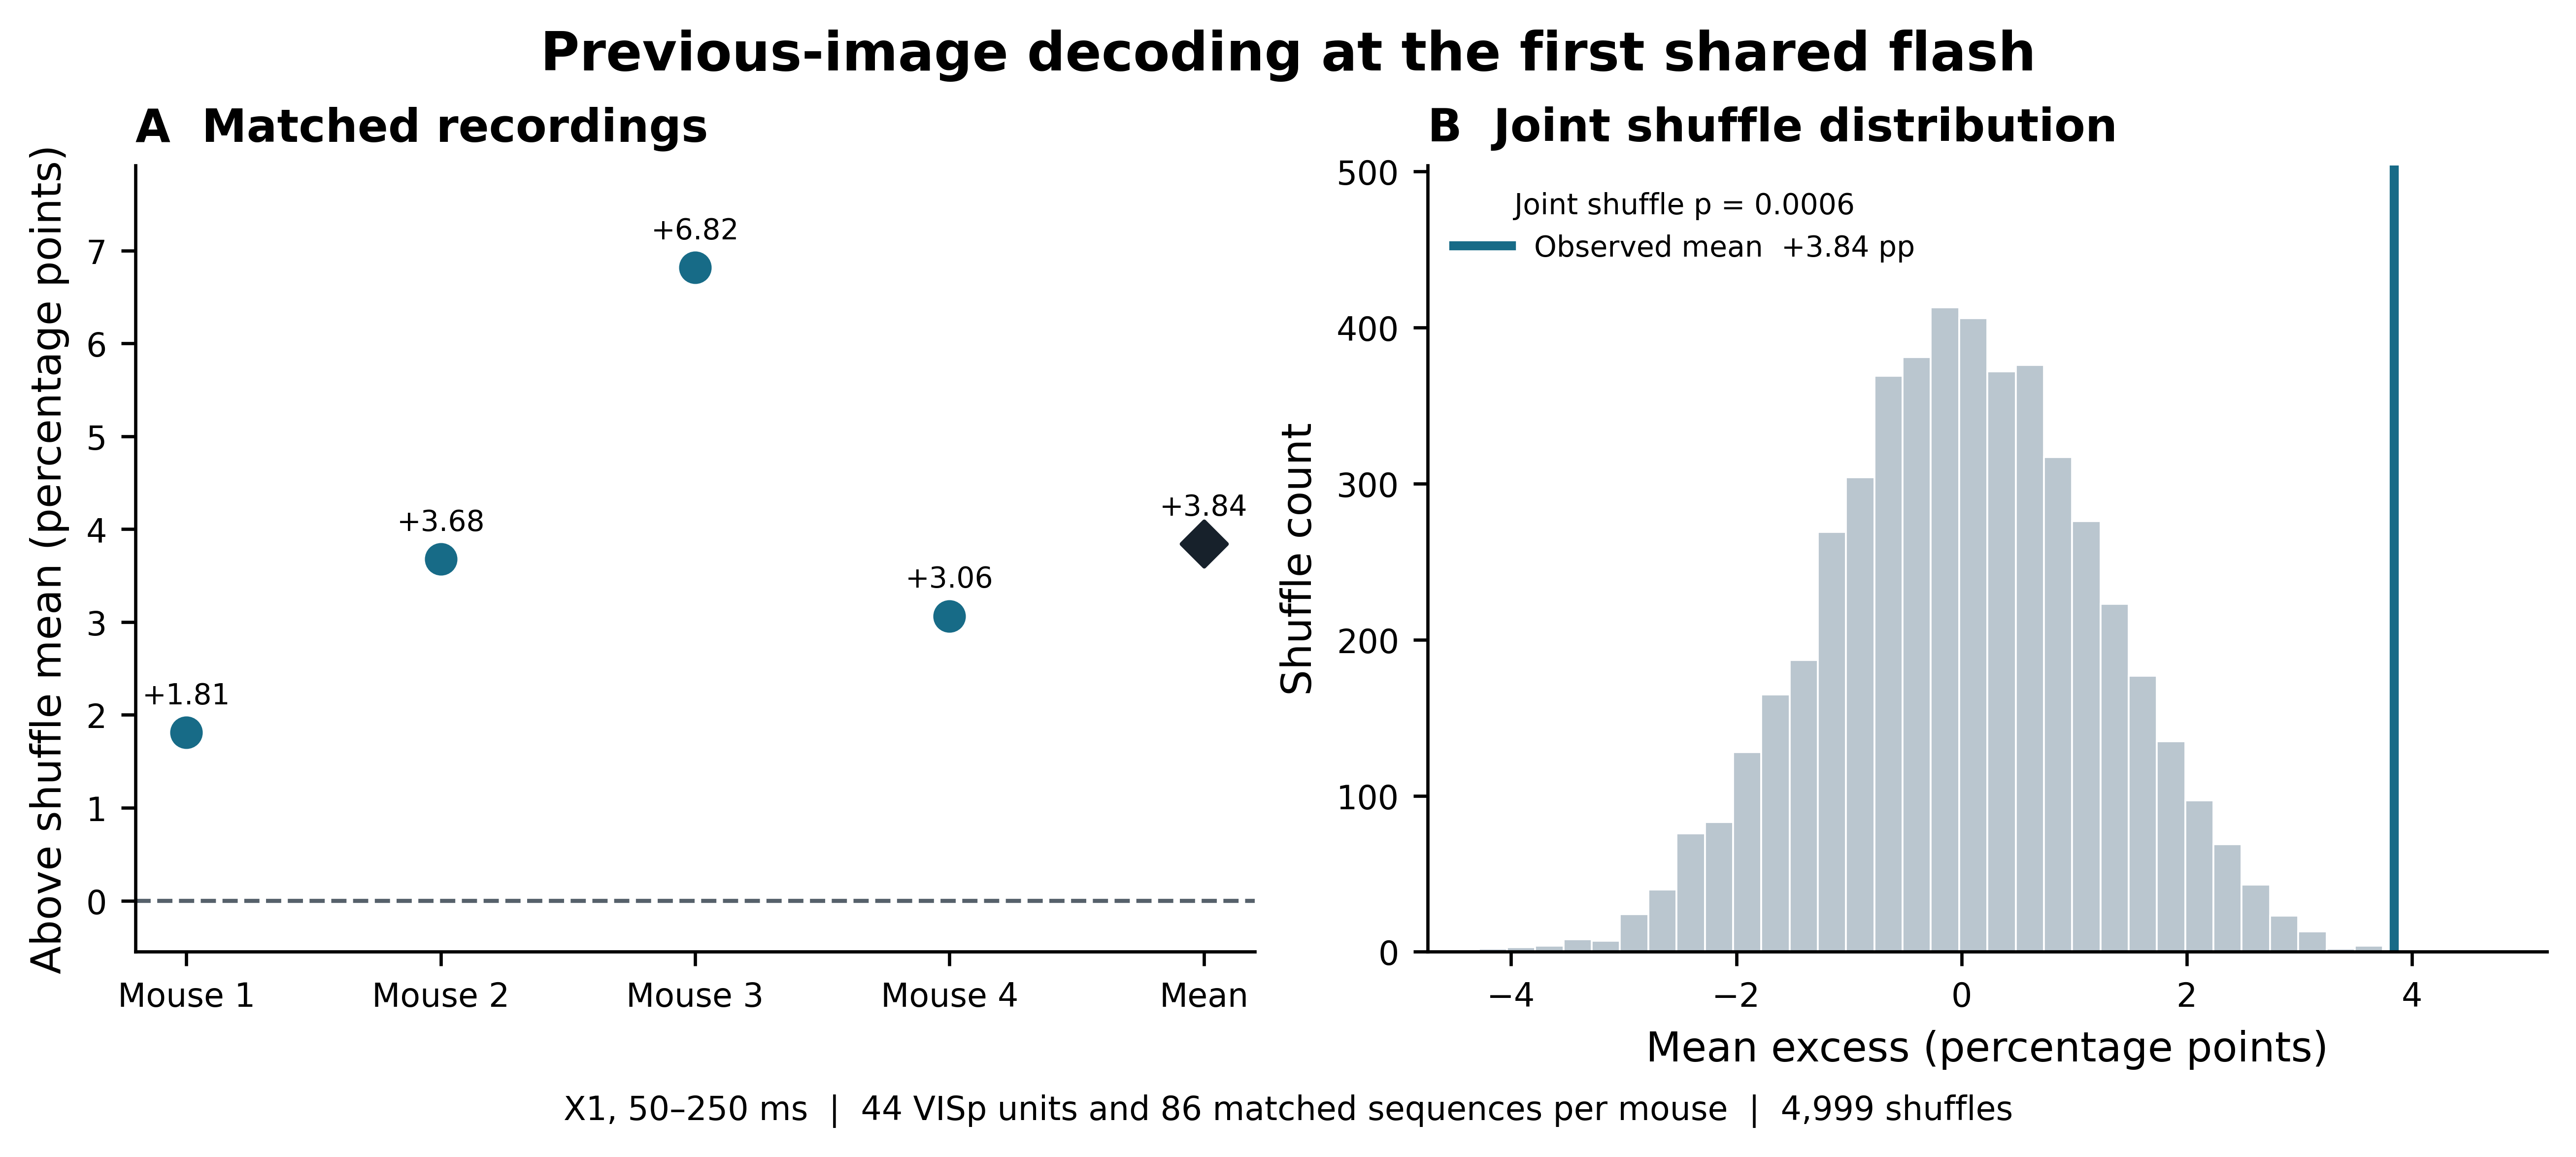

In [34]:
from IPython.display import Image, display

# Leave room above the histogram for the legend.
ax2.set_ylim(0, max(bar.get_height() for bar in ax2.patches) * 1.22)
ax2.legend(
    title=f"Joint shuffle p = {p_joint:.4f}",
    loc="upper left",
    frameon=False,
    fontsize=7,
    title_fontsize=7,
)

# Make the numbers above the points in panel A slightly smaller.
for label in ax1.texts:
    label.set_fontsize(7)

fig.savefig(png_path, dpi=600, facecolor="white", bbox_inches="tight")
display(Image(filename=str(png_path), width=900))

## Run-length-preserving permutations

In [35]:
from types import FunctionType
import h5py
import numpy as np

# Use the same onsets, labels and temporal shuffle blocks as the main analysis.
runlength_inputs = (
    (1055240613, flash_onsets[0], history, shuffle_groups),
    (1067588044, rep_times[:, 1], rep_history, rep_shuffle_groups),
    (1081090969, m3_times[:, 1], m3_history, m3_shuffle_groups),
    (1065449881, m4_times[:, 1], m4_history, m4_shuffle_groups),
)

def previous_streak_length(session_id, x1_times, previous_image):
    path = ROOT / "data" / f"ecephys_session_{session_id}.nwb"

    with h5py.File(path, "r") as f:
        table, = [
            g for name, g in f["intervals"].items()
            if "natural_images" in name.lower()
            and name.endswith("_presentations")
        ]
        all_times = table["start_time"][:]
        rows = np.flatnonzero(table["stimulus_block"][:] == 5)
        rows = rows[np.argsort(all_times[rows])]
        times = all_times[rows]
        images = table["image_name"][:][rows].astype(str)
        omitted = table["omitted"][:][rows].astype(bool)
        changes = table["is_change"][:][rows].astype(bool)

    i = np.searchsorted(times, x1_times)
    if np.any((i == 0) | (i >= len(times))):
        raise ValueError(f"X1 outside passive block in session {session_id}")

    if not (
        np.allclose(times[i], x1_times, rtol=0, atol=1e-7)
        and np.array_equal(images[i - 1], previous_image)
        and np.all(changes[i] & ~omitted[i - 1])
    ):
        raise ValueError(f"Event alignment mismatch in session {session_id}")

    # A streak breaks at an omission, image change, or irregular onset gap.
    starts = np.r_[
        True,
        (images[1:] != images[:-1])
        | omitted[1:] | omitted[:-1] | changes[1:]
        | (np.abs(np.diff(times) - 0.75) > 0.05)
    ]
    idx = np.arange(len(times))
    last_start = np.maximum.accumulate(np.where(starts, idx, 0))

    # Do not shuffle the first streak if its beginning is unobserved.
    return np.where(last_start[i - 1] > 0, i - last_start[i - 1], -1)

def constrain_by_length(blocks, lengths, labels):
    restricted = []
    for ids in blocks:
        for length in np.unique(lengths[ids]):
            if length < 1:
                continue
            same = ids[lengths[ids] == length]
            if np.unique(labels[same]).size >= 2:
                restricted.append(same)
    return restricted

block_names = (
    "shuffle_groups", "rep_shuffle_groups",
    "m3_shuffle_groups", "m4_shuffle_groups",
)
sensitivity_scope = match_four_x1.__globals__.copy()

for name, (sid, x1, labels, blocks) in zip(block_names, runlength_inputs):
    lengths = previous_streak_length(sid, x1, labels)
    restricted = constrain_by_length(blocks, lengths, labels)
    sensitivity_scope[name] = restricted
    print(
        f"{sid} | shuffleable sequences: "
        f"{sum(map(len, restricted))}/{sum(map(len, blocks))} "
        f"| {len(restricted)} blocks",
        flush=True,
    )

# Run the original decoder with only the shuffle blocks replaced.
match_x1_runlength = FunctionType(
    match_four_x1.__code__, sensitivity_scope, "match_x1_runlength"
)
four_x1_runlength = match_x1_runlength(draws=100, n_perm=4999)

np.testing.assert_allclose(
    four_x1_runlength["observed"], four_x1["observed"], rtol=0, atol=1e-12
)
assert four_x1_runlength["n_units"] == four_x1["n_units"]
assert four_x1_runlength["n_trials"] == four_x1["n_trials"]
print("Verified: observed scores, matched units and matched trials unchanged.")

1055240613 | shuffleable sequences: 6/85 | 3 blocks
1067588044 | shuffleable sequences: 25/177 | 12 blocks
1081090969 | shuffleable sequences: 10/175 | 5 blocks
1065449881 | shuffleable sequences: 12/92 | 6 blocks
Per mouse: 44 VISp units | 86 sequences | 8 current images
Mouse 1 | X1 51.1% | above shuffle mean +0.21 pp | p=0.2574 | Holm p=0.5148
Mouse 2 | X1 54.1% | above shuffle mean +0.46 pp | p=0.3486 | Holm p=0.5148
Mouse 3 | X1 57.1% | above shuffle mean +0.93 pp | p=0.1242 | Holm p=0.3776
Mouse 4 | X1 57.1% | above shuffle mean +1.04 pp | p=0.0944 | Holm p=0.3776
Equal-weight mean excess: +0.66 pp
Joint shuffle p (these four recordings): 0.0412
Verified: observed scores, matched units and matched trials unchanged.
